# Heartline | Heart Health Information Assistant
**UCS420 · Assignment 10 · Even roll numbers**

[Open in Google Colab](https://colab.research.google.com/github/doraem-on/New_cogn/blob/main/assignment10/main.ipynb). Choose **Runtime → Run all**, then use **Ask Heartline** at the end. All data and model training are inside this notebook.

Try “How do I choose a blood pressure cuff?” and then “I have chest pressure right now.” Both mention pressure. One retrieves a measurement guide. The other should interrupt the normal answer path.

This classroom prototype answers general questions in English. Its emergency phrases have limited coverage. If someone may be having a medical emergency, call local emergency services immediately.

## 1 · Training corpus
Each row below is a distinct, hand-authored question with one intent label. The final scenario suite uses separate prompts. No patient records or external model calls are used.

In [1]:
import re
from collections import Counter
from dataclasses import dataclass
from html import escape

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

examples = {
    "pressure": [
        "How do I measure blood pressure at home?", "Which size cuff should I buy?",
        "Should I sit before taking a BP reading?", "How do I position my arm for the monitor?",
        "What should a blood pressure diary contain?", "Why take two BP measurements?",
        "Are wrist monitors the best choice?", "When should I log my readings?",
        "Where does the pressure cuff go?", "Can I measure BP through a sleeve?",
        "Is there a proper way to sit for a reading?", "Can I bring my BP monitor to my appointment?",
    ],
    "lipids": [
        "What does a lipid panel test?", "Why are LDL and HDL listed separately?",
        "Is fasting necessary before cholesterol testing?", "What are triglycerides?",
        "What is included in a cholesterol screening?", "What is meant by bad cholesterol?",
        "Is a lipid profile a blood test?", "What does total cholesterol include?",
        "Who decides how often to repeat a lipid test?", "Why does LDL matter for my arteries?",
        "How is HDL different from LDL?", "How should I prepare for a cholesterol blood draw?",
    ],
    "food": [
        "How can I eat less sodium?", "Which foods belong in a heart healthy diet?",
        "What should I look for on a salt label?", "Which grains should I choose for meals?",
        "How do I compare sodium in canned soups?", "Can beans be part of a heart friendly meal?",
        "What can I eat instead of saturated fat?", "How can I season food without salt?",
        "What is a simple heart healthy breakfast?", "Which vegetables fit a healthy eating pattern?",
        "Are low sodium groceries worth looking for?", "What should I put on my plate?",
    ],
    "activity": [
        "What counts as moderate exercise?", "Is brisk walking good exercise?",
        "How can I add physical activity to my workday?", "Can short walks count as exercise?",
        "How can a beginner start being active?", "Which aerobic activities can I try?",
        "Can I increase my walking time gradually?", "What is a simple workout to start with?",
        "Does cycling count as aerobic activity?", "How can I sit less at work?",
        "How do I build up exercise after being inactive?", "How many minutes of activity do adults aim for?",
    ],
    "sleep": [
        "Why does sleep matter for my heart?", "How many hours of sleep do adults need?",
        "Can a bedtime routine improve my rest?", "Does a regular wake time matter?",
        "How can I make my bedroom better for sleep?", "Should I avoid caffeine near bedtime?",
        "Does sleeping too little affect heart health?", "What is good sleep hygiene?",
        "How can I keep a steady sleep schedule?", "What can I change if my nights are too short?",
        "Does screen time interfere with bedtime?", "Why am I told to keep my room dark at night?",
    ],
    "stress": [
        "How can I manage daily stress?", "What relaxation techniques can I try?",
        "Can meditation help me unwind?", "How do I cope with pressure at work?",
        "How can I build a calming routine?", "Could breathing exercises help with stress?",
        "What can I do about feeling overwhelmed?", "Who can I talk to about ongoing stress?",
        "What does chronic stress do to the heart?", "Can social support help with worries?",
        "How do I relax after a stressful day?", "Can mindfulness help me feel calmer?",
    ],
    "risk": [
        "Does heart disease run in families?", "Which risk factors can I change?",
        "Why does smoking raise my risk?", "Does family history of early heart disease matter?",
        "How does age affect cardiovascular risk?", "Which heart risks are inherited?",
        "Why ask about a parent's heart disease?", "Can tobacco damage my heart?",
        "How can quitting cigarettes reduce risk?", "What should I tell my doctor about my relatives?",
        "What increases the chance of coronary disease?", "Does having a sibling with heart disease matter?",
    ],
    "warnings": [
        "What are the warning signs of a heart attack?", "Which heart attack symptoms should people learn?",
        "Can heart attack discomfort come and go?", "Why is an ambulance advised for a suspected heart attack?",
        "What should a bystander know about heart attacks?", "What does a heart attack sometimes feel like?",
        "Can shortness of breath be a warning sign?", "What symptoms besides chest discomfort are possible?",
        "Can a heart attack start slowly?", "Can jaw discomfort occur during a heart attack?",
        "Why is it important to act fast on warning signs?", "How do people recognize a possible heart attack?",
    ],
}
queries = [q for group in examples.values() for q in group]
labels = [intent for intent, group in examples.items() for q in group]
assert len(set(q.casefold() for q in queries)) == len(queries)
print(f"{len(queries)} queries · {len(examples)} intents")
for intent, count in Counter(labels).items():
    print(f"{intent:10} {count:2}   {examples[intent][0]}")

96 queries · 8 intents
pressure   12   How do I measure blood pressure at home?
lipids     12   What does a lipid panel test?
food       12   How can I eat less sodium?
activity   12   What counts as moderate exercise?
sleep      12   Why does sleep matter for my heart?
stress     12   How can I manage daily stress?
risk       12   Does heart disease run in families?
warnings   12   What are the warning signs of a heart attack?


## 2 · Taxonomy, knowledge base and concept relationships
Each leaf has two reference entries. Each entry names its retrieval terms, a short answer, a source and a directed relationship. The same relationship appears in the answer inspector, so a reader can follow a question from category to evidence.

In [2]:
taxonomy = {
    "Measurements": {"pressure": "Blood pressure", "lipids": "Cholesterol tests"},
    "Daily habits": {"food": "Food choices", "activity": "Physical activity"},
    "Rest and recovery": {"sleep": "Sleep", "stress": "Stress"},
    "Risk and recognition": {"risk": "Risk factors", "warnings": "Warning signs"},
}
paths = {intent: (parent, title) for parent, leaves in taxonomy.items() for intent, title in leaves.items()}
nhlbi = "https://www.nhlbi.nih.gov/health/"
aha = "https://www.heart.org/en/health-topics/"
sources = {
    "pressure": aha + "high-blood-pressure/understanding-blood-pressure-readings/monitoring-your-blood-pressure-at-home",
    "lipids": nhlbi + "blood-cholesterol/diagnosis",
    "food": nhlbi + "heart-healthy-living/healthy-foods",
    "activity": nhlbi + "heart-healthy-living/physical-activity",
    "sleep": nhlbi + "heart-healthy-living/sleep",
    "stress": nhlbi + "heart-healthy-living/manage-stress",
    "risk": nhlbi + "heart-healthy-living/risks",
    "warnings": aha + "heart-attack/warning-signs-of-a-heart-attack",
}

@dataclass(frozen=True)
class Entry:
    title: str
    terms: str
    answer: str
    edge: tuple

kb = {
    "pressure": [
        Entry("Fit and positioning", "choose cuff size upper arm wrist monitor sleeve sitting position measure",
              "Use a validated upper-arm monitor with a cuff that fits. Rest quietly for five minutes, then place the cuff on bare skin and support your arm at heart level.",
              ("Upper-arm cuff", "measures", "Blood pressure")),
        Entry("A record you can share", "log diary repeat two readings record time appointment",
              "Take two readings a minute apart and write down both. Bring the log and monitor to your appointment so your care team can review the pattern and check the device.",
              ("Home readings", "are recorded in", "Blood pressure log")),
    ],
    "lipids": [
        Entry("What the panel measures", "lipid profile test panel triglycerides blood draw fasting screening",
              "A lipid panel measures cholesterol and triglycerides in a blood sample. Ask the ordering clinic whether you should fast and when to repeat the test.",
              ("Lipid panel", "measures", "Triglycerides")),
        Entry("Reading LDL and HDL", "ldl hdl bad good total cholesterol arteries difference",
              "LDL can contribute to cholesterol buildup in arteries. HDL helps carry cholesterol away. Your clinician interprets both values alongside your other risk factors.",
              ("LDL cholesterol", "contributes to", "Arterial plaque")),
    ],
    "food": [
        Entry("Compare sodium on labels", "salt sodium canned soup groceries seasoning label",
              "Compare sodium per serving on similar products and look for lower-sodium options. Herbs and spices can add flavor when you cook with less salt.",
              ("Excess sodium", "can raise", "Blood pressure")),
        Entry("Build a meal", "meal breakfast vegetables saturated fat beans plate whole grains eating diet",
              "Build meals around vegetables, fruit, whole grains and protein sources such as beans or fish. Use unsaturated oils in place of fats high in saturated fat.",
              ("Heart-healthy eating", "includes", "Whole grains")),
    ],
    "activity": [
        Entry("Start with a short walk", "start beginner gradually walks inactive workday sit less short",
              "Start with a manageable walk and build up gradually. A short walk during a break can help you spend less time sitting. Ask your care team about activity limits if you have a heart condition.",
              ("Walking", "is a form of", "Physical activity")),
        Entry("Count moderate activity", "moderate aerobic minutes exercise cycling brisk workout adults",
              "For most adults, a common weekly goal is at least 150 minutes of moderate aerobic activity, such as brisk walking. Activity can be spread across the week.",
              ("Brisk walking", "is an example of", "Moderate aerobic activity")),
    ],
    "sleep": [
        Entry("Plan enough time for sleep", "hours duration short nights adults too little rest",
              "Most adults need about seven to nine hours of sleep a night. If you regularly wake unrefreshed despite enough time in bed, discuss it with a healthcare professional.",
              ("Sleep duration", "is one aspect of", "Sleep health")),
        Entry("Keep a regular bedtime", "bedtime routine caffeine screen room dark schedule wake",
              "Keep bedtime and wake time consistent. Try a quiet, dark bedroom and a wind-down routine. Caffeine late in the day can interfere with sleep.",
              ("Regular sleep schedule", "supports", "Sleep health")),
    ],
    "stress": [
        Entry("Practice a relaxation technique", "relax meditate mindfulness breathing calm unwind work pressure",
              "Try a brief relaxation practice such as slow breathing or meditation. Choose a quiet moment to practice regularly so the technique feels familiar during stressful periods.",
              ("Relaxation practice", "can help manage", "Stress")),
        Entry("Find support for ongoing stress", "ongoing chronic overwhelmed support talk worries heart",
              "Persistent stress can affect heart health and daily habits. Talk with someone you trust or a healthcare professional about support that fits your situation.",
              ("Social support", "can help manage", "Stress")),
    ],
    "risk": [
        Entry("Bring your family history", "family parent sibling relative inherited age history coronary disease",
              "Age and a family history of early heart disease affect risk. Tell your clinician which relatives had heart disease and how old they were when it began.",
              ("Family history", "informs", "Cardiovascular risk")),
        Entry("Identify a changeable risk", "tobacco smoking cigarette quitting change modifiable risk factors",
              "Smoking is a risk factor you can change. Quitting helps protect your heart. A clinician can help you choose support for quitting and review other risks such as high blood pressure.",
              ("Tobacco use", "increases", "Cardiovascular risk")),
    ],
    "warnings": [
        Entry("Recognize warning signs", "symptoms signs feel chest discomfort jaw breath slowly come go recognition",
              "Possible signs include chest pressure, discomfort in the arm or jaw, or shortness of breath. Symptoms may come and go. If these are happening now, call local emergency services immediately.",
              ("Heart attack", "may cause", "Chest discomfort")),
        Entry("Get emergency help", "bystander ambulance emergency act fast suspected why call",
              "Call local emergency services immediately if a heart attack is suspected. An ambulance team can begin assessment and treatment before arrival at the hospital.",
              ("Suspected heart attack", "requires", "Emergency assessment")),
    ],
}
assert set(examples) == set(paths) == set(kb) == set(sources)
edges = {entry.edge for entries in kb.values() for entry in entries}
concepts = {term for subject, _, obj in edges for term in (subject, obj)}
print(f"{len(taxonomy)} categories · {len(paths)} leaves · {len(concepts)} concepts · {len(edges)} relationships")
for parent, leaves in taxonomy.items():
    print(f"\n{parent}")
    for intent, title in leaves.items():
        print(f"  {title}")
        for entry in kb[intent]:
            print("    " + " → ".join(entry.edge))

4 categories · 8 leaves · 28 concepts · 16 relationships

Measurements
  Blood pressure
    Upper-arm cuff → measures → Blood pressure
    Home readings → are recorded in → Blood pressure log
  Cholesterol tests
    Lipid panel → measures → Triglycerides
    LDL cholesterol → contributes to → Arterial plaque

Daily habits
  Food choices
    Excess sodium → can raise → Blood pressure
    Heart-healthy eating → includes → Whole grains
  Physical activity
    Walking → is a form of → Physical activity
    Brisk walking → is an example of → Moderate aerobic activity

Rest and recovery
  Sleep
    Sleep duration → is one aspect of → Sleep health
    Regular sleep schedule → supports → Sleep health
  Stress
    Relaxation practice → can help manage → Stress
    Social support → can help manage → Stress

Risk and recognition
  Risk factors
    Family history → informs → Cardiovascular risk
    Tobacco use → increases → Cardiovascular risk
  Warning signs
    Heart attack → may cause → Chest d

## 3 · Normalize language and learn intent
A small domain lexicon lemmatizes common inflections without a runtime download. It leaves unknown words intact. The trace shows what happens at each stage. Negation survives stopword removal. A TF-IDF matrix of unigrams and bigrams supplies features to multinomial logistic regression.

In [3]:
STOP = set(ENGLISH_STOP_WORDS) - {"no", "nor", "not", "never", "without", "cannot"}
forms = {
    "measure": "measures measuring measured", "read": "reads reading readings",
    "walk": "walks walking walked", "run": "running runs ran", "sleep": "sleeping sleeps slept",
    "choose": "choosing chose chosen", "eat": "eating eats ate", "smoke": "smokes smoking smoked",
    "quit": "quits quitting", "exercise": "exercises exercising exercised",
    "sit": "sits sitting sat", "take": "takes taking took taken", "be": "been was were is are",
    "test": "tests tested testing", "risk": "risks", "sign": "signs", "symptom": "symptoms",
    "monitor": "monitors monitoring", "meal": "meals", "grain": "grains", "minute": "minutes",
    "hour": "hours", "relative": "relatives", "artery": "arteries", "factor": "factors",
    "vegetable": "vegetables", "food": "foods", "cigarette": "cigarettes",
    "technique": "techniques", "attack": "attacks", "worry": "worries", "adult": "adults",
}
lemma = {form: base for base, variants in forms.items() for form in variants.split()}

def stages(text):
    lower = text.lower().replace("’", "'").replace("can't", "cannot").replace("n't", " not")
    tokens = re.findall(r"[a-z]+|\d+", lower)
    kept = [word for word in tokens if word not in STOP]
    return lower, tokens, kept, [lemma.get(word, word) for word in kept]

def tokenize(text):
    return stages(text)[-1]

for stage, value in zip(["Lowercase", "Tokens", "After stopwords", "Lemmas"],
                        stages("Does WALKING after meals help, or should I avoid walks?")):
    print(f"{stage:15} {value}")

model = make_pipeline(
    TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                    ngram_range=(1, 2), sublinear_tf=True),
    LogisticRegression(C=8, max_iter=1000, random_state=420),
)

Lowercase       does walking after meals help, or should i avoid walks?
Tokens          ['does', 'walking', 'after', 'meals', 'help', 'or', 'should', 'i', 'avoid', 'walks']
After stopwords ['does', 'walking', 'meals', 'help', 'avoid', 'walks']
Lemmas          ['does', 'walk', 'meal', 'help', 'avoid', 'walk']


## 4 · Evaluate before training the demo model
Five stratified folds produce one out-of-fold prediction for every question. Each fold fits its own vocabulary, IDF weights and classifier on its training rows. The heatmap and error examples below use those held-out predictions. The interactive model is subsequently refit on the full corpus.

This evaluation measures closed-set intent classification on authored English questions. The separate scenario suite exercises retrieval and routing. Neither evaluation establishes clinical safety.

              precision    recall  f1-score   support

    pressure      0.923     1.000     0.960        12
      lipids      0.909     0.833     0.870        12
        food      0.846     0.917     0.880        12
    activity      0.667     0.833     0.741        12
       sleep      0.818     0.750     0.783        12
      stress      0.700     0.583     0.636        12
        risk      1.000     0.833     0.909        12
    warnings      0.923     1.000     0.960        12

    accuracy                          0.844        96
   macro avg      0.848     0.844     0.842        96
weighted avg      0.848     0.844     0.842        96



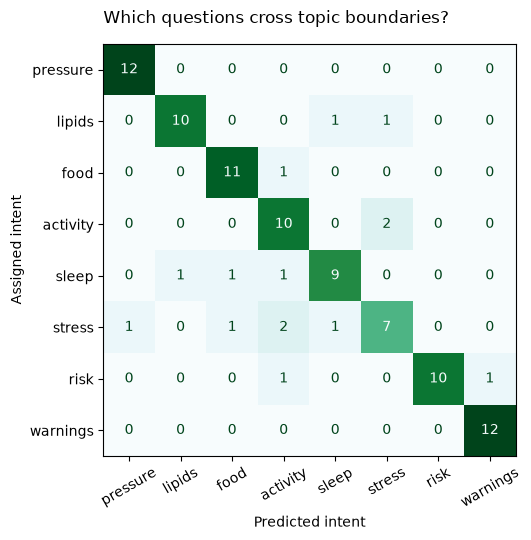

lipids → stress  |  What are triglycerides?
lipids → sleep  |  Why does LDL matter for my arteries?
food → activity  |  What should I put on my plate?
activity → stress  |  Which aerobic activities can I try?
activity → stress  |  How can I sit less at work?
sleep → lipids  |  Does a regular wake time matter?


In [4]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=420)
prediction = cross_val_predict(model, queries, labels, cv=folds)
order = list(examples)
print(classification_report(labels, prediction, labels=order, digits=3, zero_division=0))
matrix = confusion_matrix(labels, prediction, labels=order)
fig, ax = plt.subplots(figsize=(8.4, 5.5))
ConfusionMatrixDisplay(matrix, display_labels=order).plot(
    ax=ax, colorbar=False, cmap="BuGn", values_format="d", xticks_rotation=30)
ax.set_title("Which questions cross topic boundaries?", loc="left", pad=15)
ax.set_xlabel("Predicted intent")
ax.set_ylabel("Assigned intent")
fig.tight_layout()
plt.show()
errors = [(q, y, pred) for q, y, pred in zip(queries, labels, prediction) if y != pred]
for q, y, pred in errors[:6]:
    print(f"{y} → {pred}  |  {q}")
model.fit(queries, labels)
vectorizer, classifier = model.steps[0][1], model.steps[1][1]

## 5 · Route a question and retrieve evidence
Emergency phrases take priority over every other rule. Empty inputs, personal treatment decisions, unsupported topics and uncertain classifications have separate responses. For accepted queries, the highest cosine similarity within the predicted topic selects a reference entry. If no entry has matching words, the assistant offers the two available subtopics. The class score describes the model's text match, not the likelihood of a health condition.

In [5]:
@dataclass
class Reply:
    route: str
    text: str
    intent: str = ""
    source: str = ""
    trace: str = ""

entry_index = {}
for intent, entries in kb.items():
    index = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False)
    vectors = index.fit_transform([f"{e.title} {e.terms} {e.answer}" for e in entries])
    entry_index[intent] = index, vectors

red_flags = re.compile(
    r"\b(?:chest (?:pain|pressure|tightness|discomfort|aches?|hurts?|feels? (?:tight|heavy)|is tight)"
    r"|(?:pain|pressure|tightness|squeezing|crushing) (?:in|on|across) (?:my |the |his |her )?chest"
    r"|(?:can(?:not|'t)|struggling to) breathe|(?:shortness of|short of|out of) breath"
    r"|trouble breathing|difficulty breathing|gasping for (?:air|breath)|having a heart attack|(?:unconscious|unresponsive)|collapsed)\b")
emergency_answer = ("If this is happening now or has just happened, call your local emergency "
                    "number immediately and ask for an ambulance. Follow the dispatcher's instructions.")
education = re.compile(r"^(?:what (?:are|is|does)|which|why|can|how (?:do people|can someone))\b")
personal = re.compile(r"\b(?:i|my|me|we|he|she|they|someone here|right now|currently|today)\b")
unsupported = re.compile(r"\b(?:rash|eczema|migraine|insulin|acne|toothache|pregnancy test|sprain|antibiotics?)\b")
treatment = re.compile(
    r"\b(?:dos(?:e|es|age)|prescri(?:be|ption)|diagnos(?:e|is)|how (?:much|many) (?:aspirin|pills?)"
    r"|(?:stop|start|double|skip|adjust|change|take|switch)\b.{0,35}\b"
    r"(?:medicines?|medications?|tablets?|pills?|statins?|aspirin|beta blockers?|lisinopril))\b")
domain_terms = set().union(*(set(tokenize(e.terms)) for entries in kb.values() for e in entries))
domain_terms.update("heart cardiac cardiovascular health bp lipid cholesterol stress sleep activity exercise".split())
topic_list = ", ".join(title.lower() for _, title in paths.values())

def ask(question):
    text = " ".join(question.lower().replace("’", "'").split())
    informative = education.search(text) and not personal.search(text)
    # Ignore narrowly scoped denials while still checking every other symptom.
    symptoms = re.sub(r"\b(?:no|without|denies)\s+(?:chest pain|shortness of breath)\b", "", text)
    if red_flags.search(symptoms) and not informative:
        return Reply("emergency", emergency_answer, source=sources["warnings"], trace="Urgent symptom phrase")
    if red_flags.search(symptoms) and informative:
        entry = kb["warnings"][0]
        return Reply("answer", entry.answer, "warnings", sources["warnings"], "General warning-sign question")
    if not text:
        return Reply("empty", "Enter a question or choose one of the example topics.")
    # A very high reported BP merits specific escalation even without a chest-symptom phrase.
    bp = re.search(r"\b(\d{2,3})\s*(?:/|over)\s*(\d{2,3})\b", text)
    if bp and (int(bp[1]) > 180 or int(bp[2]) > 120):
        return Reply("urgent reading", "If there is new weakness, vision change, trouble speaking, "
                     "chest pain or trouble breathing, call local emergency services now. Otherwise "
                     "repeat the reading after at least one minute. If it remains this high, contact "
                     "a healthcare professional immediately.", source=sources["pressure"])
    if treatment.search(text) or bp:
        return Reply("personal care", "A clinician or pharmacist can review your readings and medicines "
                     "in context. Contact your care team for personal interpretation or changes to treatment.")
    tokens = set(tokenize(text))
    features = vectorizer.transform([text])
    if unsupported.search(text) or not tokens.intersection(domain_terms) or features.nnz == 0:
        return Reply("unsupported", f"This guide covers {topic_list}. Try a question about one of these.")
    probabilities = model.predict_proba([text])[0]
    first, second = np.argsort(probabilities)[-2:][::-1]
    best, runner = classifier.classes_[[first, second]]
    score, gap = probabilities[first], probabilities[first] - probabilities[second]
    trace = f"{paths[best][1]} {score:.2f} · {paths[runner][1]} {probabilities[second]:.2f}"
    if score < 0.27 or gap < 0.08:
        return Reply("clarify", f"Could you be more specific? Two possible topics are "
                     f"{paths[best][1].lower()} and {paths[runner][1].lower()}.", trace=trace)
    index, vectors = entry_index[best]
    similarity = (vectors @ index.transform([text]).T).toarray().ravel()
    if similarity.max() == 0:
        topics = " or ".join(e.title.lower() for e in kb[best])
        return Reply("clarify", f"Which would you like to explore: {topics}?", trace=trace)
    entry = kb[best][int(similarity.argmax())]
    path = " → ".join(paths[best])
    reason = f"{path} · {entry.title} | {trace} | " + " → ".join(entry.edge)
    return Reply("answer", entry.answer, best, sources[best], reason)

## 6 · Scenario bench
Each row sends a new query through the complete assistant. The checks cover all eight intents, a paraphrase, an unsupported healthcare topic, an ambiguous prompt, emergency escalation and additional rule boundaries. Each accepted answer must retrieve evidence from its assigned topic.

In [6]:
cases = [
    ("Which cuff fits my upper arm?", "answer", "pressure"),
    ("What does my lipid panel measure?", "answer", "lipids"),
    ("Is there less sodium in some soups?", "answer", "food"),
    ("Does a brisk walk count as moderate activity?", "answer", "activity"),
    ("Can I set a regular bedtime?", "answer", "sleep"),
    ("What relaxation practice helps manage stress?", "answer", "stress"),
    ("Does smoking increase cardiovascular risk?", "answer", "risk"),
    ("Can a heart attack cause jaw discomfort?", "answer", "warnings"),
    ("What can replace salt when seasoning dinner?", "answer", "food"),
    ("What cream should I use for eczema?", "unsupported", ""),
    ("What about my heart?", "clarify", ""),
    ("I have crushing chest pain right now.", "emergency", ""),
    ("Should I double my pills? I can't breathe.", "emergency", ""),
    ("Should I change my statin dose?", "personal care", ""),
    ("My BP is 192/122.", "urgent reading", ""),
    ("I have no chest pain but I am gasping for air.", "emergency", ""),
    ("I have no chest pain. Which BP cuff fits my arm?", "answer", "pressure"),
    ("", "empty", ""),
]
assert all(q.casefold() not in {x.casefold() for x in queries} for q, _, _ in cases)
assert {label for _, route, label in cases if route == "answer"} == set(examples)
for query, route, intent in cases:
    result = ask(query)
    assert (result.route, result.intent) == (route, intent), (query, result)
    if intent:
        assert result.source == sources[intent]
    print(f"{result.route:14} {result.intent:10} {query or '(empty)'}")
print(f"\n{len(cases)} scenario checks passed.")

# Within one intent, different questions should retrieve different answers.
cuff = ask("Which cuff fits my upper arm?")
log = ask("How should I log my BP readings?")
assert cuff.intent == log.intent == "pressure"
assert "Upper-arm cuff" in cuff.trace and "Blood pressure log" in log.trace
print("Evidence check passed: cuff fitting and keeping a log retrieve different entries.")

answer         pressure   Which cuff fits my upper arm?
answer         lipids     What does my lipid panel measure?
answer         food       Is there less sodium in some soups?
answer         activity   Does a brisk walk count as moderate activity?
answer         sleep      Can I set a regular bedtime?
answer         stress     What relaxation practice helps manage stress?
answer         risk       Does smoking increase cardiovascular risk?
answer         warnings   Can a heart attack cause jaw discomfort?
answer         food       What can replace salt when seasoning dinner?
unsupported               What cream should I use for eczema?
clarify                   What about my heart?
emergency                 I have crushing chest pain right now.
emergency                 Should I double my pills? I can't breathe.
personal care             Should I change my statin dose?
urgent reading            My BP is 192/122.
emergency                 I have no chest pain but I am gasping for air.

## 7 · Ask Heartline
In Colab, type a question in the form below and run its cell. Change the question and run the same cell again. The most recent five replies appear newest first. Select **show_reasoning** to inspect the route, class scores when available, and concept relationship. In Jupyter, edit the question string and rerun the cell.

For a live demonstration, start with “How should I log my BP readings?”, then try “What about my heart?” and “I have chest pressure right now.” Use fictional questions in any notebook you plan to share.

In [7]:
history = []

def answer_card(question, reply, show_reasoning):
    urgent = reply.route in {"emergency", "urgent reading"}
    accent = "#ab321e" if urgent else "#176e65"
    title = paths[reply.intent][1] if reply.intent else {
        "clarify": "Clarifying question", "unsupported": "Outside this guide",
        "personal care": "Ask your care team", "emergency": "Seek emergency help",
        "urgent reading": "Very high reading", "empty": "Ask a question",
    }[reply.route]
    link = ""
    if reply.source:
        publisher = "American Heart Association" if "heart.org/" in reply.source else "NHLBI"
        link = f'<a href="{escape(reply.source)}" style="color:#125b54">{publisher} reference ↗</a>'
    reasoning = ""
    if show_reasoning:
        reason = escape(reply.trace or "Handled by a rule before intent classification.")
        reasoning = f'<p style="color:#415354;font-size:13px">Route · {escape(reply.route)}<br>{reason}</p>'
    return (f'<article style="max-width:680px;background:#f7faf8;color:#192f2d;padding:16px 20px;'
            f'margin:10px 0;border-left:4px solid {accent}">'
            f'<div style="font-size:13px;color:#415354">{escape(question) or "(empty question)"}</div>'
            f'<h3 style="margin:8px 0;color:{accent}">{escape(title)}</h3>'
            f'<p>{escape(reply.text)}</p>{link}{reasoning}</article>')

def submit(question, show_reasoning=True):
    history.append((question, ask(question)))
    del history[:-5]
    return HTML("".join(answer_card(q, reply, show_reasoning) for q, reply in reversed(history)))

In [8]:
# @title Ask Heartline
question = "How should I log my BP readings?" # @param {type:"string"}
show_reasoning = True # @param {type:"boolean"}
display(submit(question, show_reasoning))